# Basic Correlation

Correlation measures how strongly two variables move together in a **straight-line** relationship.
Pearson's correlation coefficient, *r*, ranges from -1 to +1:

* **r near +1**: as x goes up, y goes up (positive correlation)
* **r near -1**: as x goes up, y goes down (negative correlation)
* **r near 0**: no linear relationship

Below we build three made-up datasets (positive, negative, and no correlation) and measure r for each.

In [1]:
# Import packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from scipy.stats import t
from scipy.stats import ttest_1samp

# Fix the random seed so the "random" numbers are the same every time the
# notebook is run. Remove this line if you want different numbers on each run.
np.random.seed(42)

## Positive correlation

In [2]:
# 1000 random integers from 0 to 49.
# Note: np.random.randint(low, high, size) EXCLUDES the high value, so 50 itself is never drawn.
x = np.random.randint(0, 50, 1000)

In [3]:
# Positive correlation with some noise:
# y is x plus random noise drawn from a normal distribution (mean 0, standard deviation 10).
# Without the noise, y would equal x exactly and r would be exactly 1.
y_pos = x + np.random.normal(0, 10, 1000)

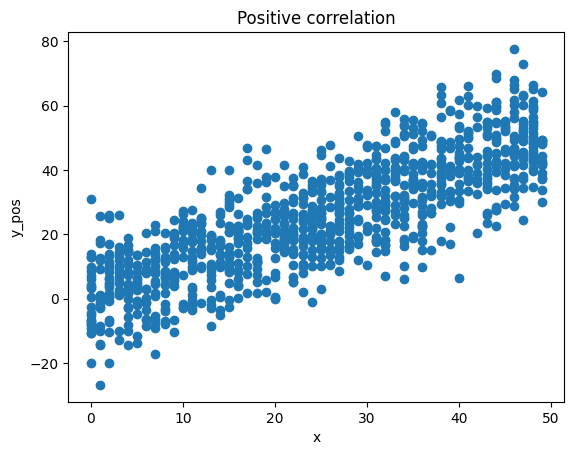

In [4]:
# Scatter plot: the cloud of points slopes upward from left to right
plt.scatter(x, y_pos)
plt.xlabel('x')
plt.ylabel('y_pos')
plt.title('Positive correlation')
plt.show()

In [5]:
# We can calculate r (and its p-value) using scipy's pearsonr function.
#   r       -> strength and direction of the linear relationship
#   p-value -> probability of seeing an r at least this far from 0 if the
#              true correlation were actually 0 (null hypothesis: no correlation)
r, p_value = pearsonr(x, y_pos)
print('r =', r)
print('p-value =', p_value)

r = 0.8101435222157062
p-value = 1.0630495901638522e-233


In [6]:
# We can also create a correlation matrix with numpy.
# Each entry is the correlation between one pair of variables:
# |x,x|x,y|
# |y,x|y,y|
# The diagonal is always 1 (every variable is perfectly correlated with itself)
# and the matrix is symmetric (corr(x,y) == corr(y,x)).
np.corrcoef(x, y_pos)

array([[1.        , 0.81014352],
       [0.81014352, 1.        ]])

In [7]:
# We can do this with pandas as well.
# Put the two variables in a DataFrame, then .corr() returns the correlation matrix.
corr_df = pd.DataFrame({'x': x, 'y': y_pos})
corr_df.corr()

,x,y
x,1.000000,0.810144
y,0.810144,1.000000


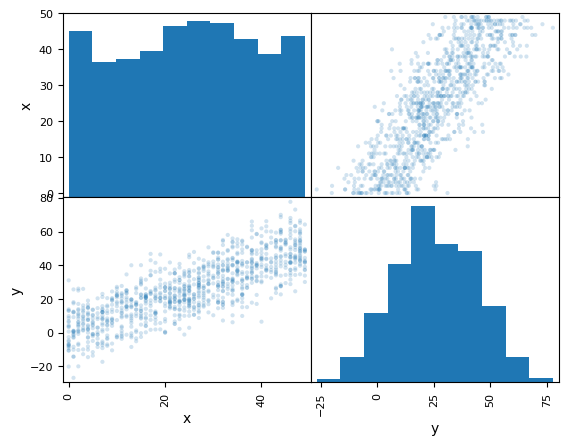

In [8]:
# We can use a scatter matrix to visualize this.
# Off-diagonal panels: scatter plot of each pair of variables.
# Diagonal panels: histogram of each variable on its own.
# alpha=0.2 makes the points see-through so dense areas show up darker.
pd.plotting.scatter_matrix(corr_df, alpha=0.2)
plt.show()

## Negative correlation

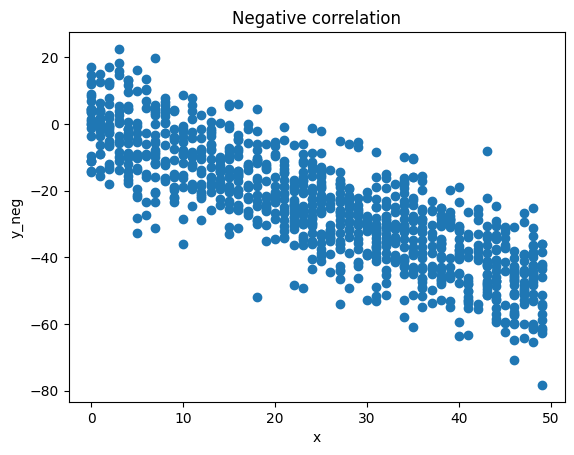

In [9]:
# Negative correlation: y is MINUS x plus the same kind of noise,
# so y goes down as x goes up and the points slope downward.
y_neg = -x + np.random.normal(0, 10, 1000)
plt.scatter(x, y_neg)
plt.xlabel('x')
plt.ylabel('y_neg')
plt.title('Negative correlation')
plt.show()

In [10]:
# r is now close to -1 (strong negative correlation)
r, p_value = pearsonr(x, y_neg)
print('r =', r)
print('p-value =', p_value)

r = -0.8268637744564672
p-value = 1.0754544324922143e-251


## No correlation

In [11]:
# No correlation: x and y are generated completely independently of each other.
# (New variable names are used so we do not overwrite the x from the cells above.)
x_rand = np.random.randint(0, 50, 1000)
y_rand = np.random.normal(0, 50, 1000)

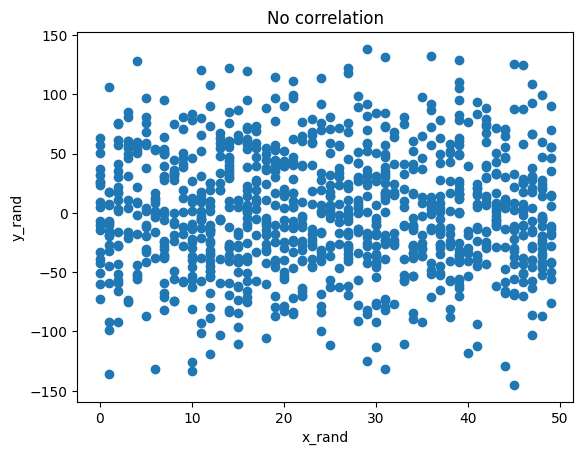

In [12]:
# The points form a shapeless cloud with no upward or downward trend
plt.scatter(x_rand, y_rand)
plt.xlabel('x_rand')
plt.ylabel('y_rand')
plt.title('No correlation')
plt.show()

In [13]:
# r should be close to 0.
# Caution: with a large sample (n=1000) even a tiny r can sometimes come out with
# a p-value below 0.05 just by chance. A small p-value only says r is unlikely to be
# exactly 0; it does NOT say the relationship is strong. Always look at the size of r too.
r, p_value = pearsonr(x_rand, y_rand)
print('r =', r)
print('p-value =', p_value)

r = -0.005690010402558496
p-value = 0.8573799788609253


# P-Value and Statistical Inference

Let's use Python to bring in some data and calculate the p-value for a given null hypothesis.

In [14]:
# Load the customer churn dataset straight from the web.
# na_values tells pandas which strings should be treated as missing values (NaN).
na_values = [' ', 'NaN', 'N/A']
churn = pd.read_csv('https://gitlab.com/CEADS/DrKerby/python/raw/master/churn.txt', na_values=na_values)
churn.head()   # show the first 5 rows

,State,Account Length,Area Code,Phone,Int'l Plan,VMail Plan,VMail Message,Day Mins,Day Calls,Day Charge,...,Eve Calls,Eve Charge,Night Mins,Night Calls,Night Charge,Intl Mins,Intl Calls,Intl Charge,CustServ Calls,Churn?
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False.
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False.
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False.
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False.
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False.


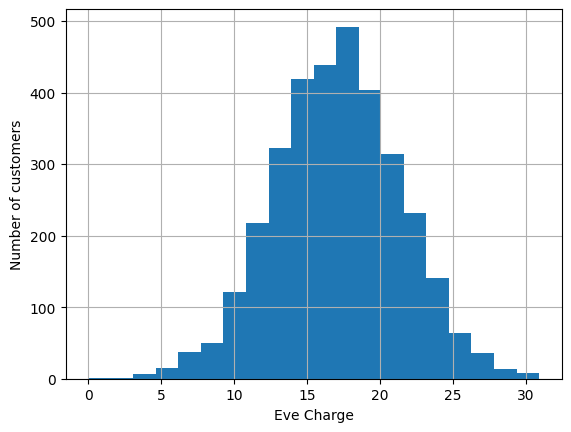

In [15]:
# Histogram of the evening charge for every customer in the dataset
churn['Eve Charge'].hist(bins=20)
plt.xlabel('Eve Charge')
plt.ylabel('Number of customers')
plt.show()

In [16]:
# For the purposes of this lecture, this churn dataset will be our POPULATION.
# Let's take a quick look at the average value of this data.
# mu is the usual symbol for a population mean.
mu = churn['Eve Charge'].mean()
mu

np.float64(17.083540354035403)

Based on this mean, we set up our hypotheses about the population that a sample is drawn from:

* **Null hypothesis (H0):** the sample comes from a population whose mean Eve Charge is mu (about 17.08).
* **Alternative hypothesis (H1):** the sample comes from a population whose mean is **not** mu.

Because H1 says "not equal" (it could be higher *or* lower), this is a **two-tailed** test.

Note that a sample mean will almost never equal mu exactly. The question is whether the difference is
bigger than we would expect from random sampling alone.

In [17]:
# Take a random sample of n=100 rows from the dataset.
# .sample() picks rows at random; replace=True means sampling WITH replacement
# (the same row can be picked more than once).
n = 100
sample = churn.sample(n=n, replace=True)
sample.head()

,State,Account Length,Area Code,Phone,Int'l Plan,VMail Plan,VMail Message,Day Mins,Day Calls,Day Charge,...,Eve Calls,Eve Charge,Night Mins,Night Calls,Night Charge,Intl Mins,Intl Calls,Intl Charge,CustServ Calls,Churn?
2063,MD,90,415,353-3203,no,no,0,114.4,122,19.45,...,154,10.85,253.1,109,11.39,10.1,5,2.73,2,False.
3222,UT,61,415,349-3843,yes,yes,29,128.2,119,21.79,...,83,14.59,250.9,114,11.29,11.7,6,3.16,3,False.
935,MD,86,408,329-2789,no,no,0,226.3,88,38.47,...,107,18.96,255.6,92,11.50,13.0,3,3.51,4,False.
253,MI,86,510,349-2808,no,yes,41,119.0,101,20.23,...,134,19.55,236.9,58,10.66,9.5,3,2.57,0,False.
1211,ND,94,408,408-9463,no,no,0,174.0,85,29.58,...,114,20.49,207.8,94,9.35,7.9,1,2.13,1,False.


In [18]:
# Check the mean of our sample (x_bar is the usual symbol for a sample mean)
x_bar = sample['Eve Charge'].mean()
x_bar

np.float64(17.740099999999998)

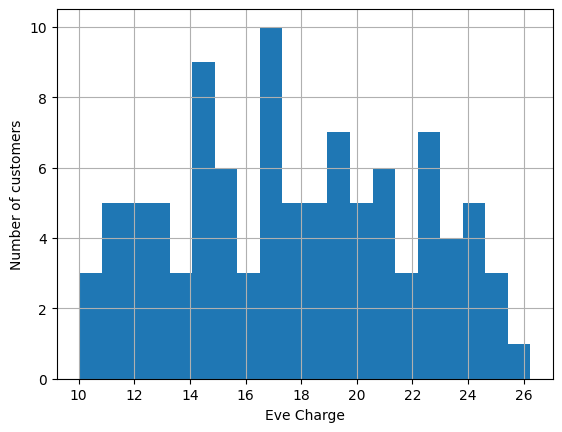

In [19]:
# The sample mean is fairly close to the population mean.
# Check the distribution of the sample data.
sample['Eve Charge'].hist(bins=20)
plt.xlabel('Eve Charge')
plt.ylabel('Number of customers')
plt.show()

The shape of this sample is a bit different from the entire dataset, because it only has 100 points.
Let's take the mean of many samples of our data. We will also calculate the t-value for each sample.

In [20]:
# This is a ONE-SAMPLE t-test: it compares the mean of a single sample (x_bar)
# against a known/hypothesized population mean (mu).
# (Comparing two groups of data against each other would be a two-sample t-test.)
#
# The formula for the t-value is:
#     t = (x_bar - mu) / (s / sqrt(n))
# where s is the sample standard deviation and n is the sample size.
# s / sqrt(n) is called the standard error of the mean.
#
# Repeat the sampling 3000 times and store the mean and t-value of each sample.
x_bars = []     # sample means
t_values = []   # t-value of each sample
for i in range(3000):
    sample_i = churn.sample(n=n, replace=True)
    sample_mean = sample_i['Eve Charge'].mean()
    sample_std = sample_i['Eve Charge'].std()    # pandas .std() uses n-1 (sample std), which is what we want
    x_bars.append(sample_mean)
    t_values.append((sample_mean - mu) / (sample_std / np.sqrt(n)))

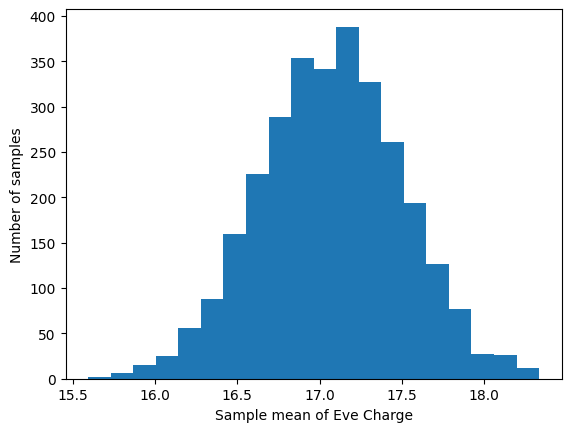

In [21]:
# Visualize the sample means.
# They pile up in a bell shape centered on mu (the Central Limit Theorem),
# and they are much less spread out than the individual data points.
plt.hist(x_bars, bins=20)
plt.xlabel('Sample mean of Eve Charge')
plt.ylabel('Number of samples')
plt.show()

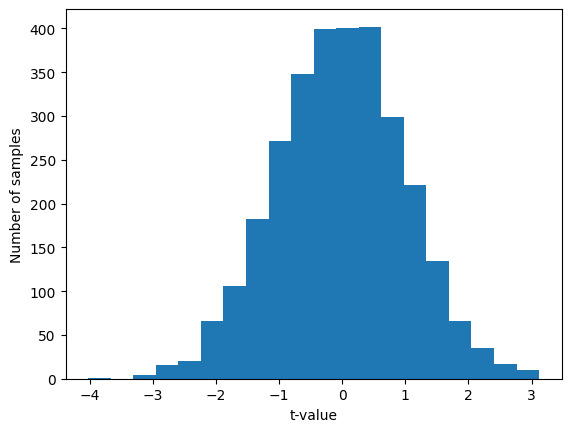

In [22]:
# Visualize the t-values.
# Because every sample really does come from a population with mean mu (H0 is true here),
# the t-values are centered on 0 and follow a t distribution with n-1 degrees of freedom.
plt.hist(t_values, bins=20)
plt.xlabel('t-value')
plt.ylabel('Number of samples')
plt.show()

SciPy has a **Percent Point Function** (`ppf`, the inverse of the cumulative distribution function)
which we can use to calculate the **critical value** of t. The critical value is the cut-off that we
compare our test statistic against: if |t| is bigger than the critical value, we reject the null hypothesis.

In [23]:
# For a 95% confidence level, alpha = 5%. In a TWO-tailed test that 5% is split
# evenly between the two tails: 2.5% in the lower tail and 2.5% in the upper tail.
# So the upper critical value is the point with 97.5% of the distribution below it,
# which is why we pass 0.975 (not 0.95) to ppf.
alpha = 0.05
p = 1 - alpha / 2      # 0.975 -> two-tailed 95% confidence level
dof = n - 1            # degrees of freedom = n - 1 = 99
                       # (named dof, not df, so it does not get confused with a DataFrame)
t_critical = t.ppf(p, dof)
t_critical

np.float64(1.9842169515086827)

In [24]:
# Check the claim: if H0 is true, about 95% of the t-values should fall
# between -t_critical and +t_critical.
t_values = np.array(t_values)
inside = np.mean(np.abs(t_values) <= t_critical)
print('Fraction of t-values within +/- t_critical:', inside)
print('Fraction outside (wrongly rejecting a true H0):', 1 - inside)
# The fraction outside should be close to alpha (0.05). This is the Type I error rate:
# even when H0 is true, about 5% of samples will lead us to reject it by chance.

Fraction of t-values within +/- t_critical: 0.9503333333333334
Fraction outside (wrongly rejecting a true H0): 0.04966666666666664


Let's compare to a t table. In a printed t table, look up the row for the degrees of freedom
(99, or the nearest row, usually 100) and the column for a two-tailed alpha of 0.05
(the same column is labelled 0.025 for one tail). The value there is about 1.984, which matches `t_critical`.

## Calculating the p-value

The **p-value** is the probability of getting a t-value at least as extreme as the one we observed,
assuming the null hypothesis is true. The decision rule is:

* **p-value < alpha (0.05)**, which is the same as **|t| > t_critical**: reject the null hypothesis.
* **p-value >= alpha (0.05)**, which is the same as **|t| <= t_critical**: fail to reject the null hypothesis.

Failing to reject does not prove the null hypothesis is true; it only means the sample does not give
enough evidence against it.

In [25]:
# t-value for the single sample of 100 that we took earlier
s = sample['Eve Charge'].std()               # sample standard deviation
t_stat = (x_bar - mu) / (s / np.sqrt(n))

# Two-tailed p-value: the area in BOTH tails beyond |t_stat|.
# t.sf is the survival function (1 - cdf), i.e. the area in the upper tail.
# Multiply by 2 to include the matching lower tail.
p_val = 2 * t.sf(abs(t_stat), dof)

print('t statistic =', t_stat)
print('t critical  =', t_critical)
print('p-value     =', p_val)

if p_val < alpha:
    print('p-value < alpha: reject the null hypothesis')
else:
    print('p-value >= alpha: fail to reject the null hypothesis')

t statistic = 1.570518349158167
t critical  = 1.9842169515086827
p-value     = 0.1194852987162764
p-value >= alpha: fail to reject the null hypothesis


In [26]:
# SciPy can do the whole one-sample t-test in one line.
# The statistic and p-value should match the ones we calculated by hand above.
ttest_1samp(sample['Eve Charge'], mu)

TtestResult(statistic=np.float64(1.5705183491581667), pvalue=np.float64(0.11948529871627647), df=np.int64(99))

The p-value is a very important consideration when performing statistical analysis.
The U.S. Census uses the following rules for p-values:

1. P-values below 0.01 constitute strong evidence against our null.
2. P-values between 0.01 and 0.05 constitute moderate evidence against our null.
3. P-values between 0.05 and 0.1 constitute weak evidence against our null.